In [1]:
import pandas as pd
from pathlib import Path

DATA = Path("../data/raw")

# Fichier -> colonne qui identifie une ligne de manière unique
fichiers = {
    "application_train.csv":     "SK_ID_CURR",
    "application_test.csv":      "SK_ID_CURR",
    "bureau.csv":                "SK_ID_BUREAU",
    "bureau_balance.csv":        None,
    "previous_application.csv":  "SK_ID_PREV",
    "POS_CASH_balance.csv":      None,
    "installments_payments.csv": None,
    "credit_card_balance.csv":   None,
}

resume = []
for nom, cle in fichiers.items():
    df = pd.read_csv(DATA / nom)
    resume.append({
        "fichier": nom,
        "lignes": df.shape[0],
        "colonnes": df.shape[1],
        "memoire_Mo": round(df.memory_usage(deep=True).sum() / 1e6),
        "%_vides": round(df.isna().mean().mean() * 100, 1),
        "lignes_dupliquees": df.duplicated().sum(),
        "cle_unique": df[cle].is_unique if cle else "n/a",
    })
    del df  # libère la mémoire

pd.DataFrame(resume)

,fichier,lignes,colonnes,memoire_Mo,%_vides,lignes_dupliquees,cle_unique
0,application_train.csv,307511,122,341,24.4,0,True
1,application_test.csv,48744,121,54,23.8,0,True
2,bureau.csv,1716428,17,285,13.5,0,True
3,bureau_balance.csv,27299925,3,682,0.0,0,n/a
4,previous_application.csv,1670214,37,704,18.0,0,True
5,POS_CASH_balance.csv,10001358,8,702,0.1,0,n/a
6,installments_payments.csv,13605401,8,871,0.0,0,n/a
7,credit_card_balance.csv,3840312,23,730,6.7,0,n/a


### Inventaire des données
- 8 tables, aucune ligne dupliquée, clés primaires uniques (SK_ID_CURR, SK_ID_BUREAU, SK_ID_PREV).
- `application_train` : 307 511 clients avec TARGET ; `application_test` : 48 744 clients sans TARGET (non utilisé pour l'entraînement ni l'évaluation).
- Les tables secondaires sont en relation 1-N avec le client (historiques de crédits et mensuels).
  → Elles devront être **agrégées par client** avant jointure, pour garder 1 ligne = 1 client.
- ~24 % de valeurs manquantes dans `application`, à analyser colonne par colonne.

In [2]:
train = pd.read_csv(DATA / "application_train.csv")
print(train["TARGET"].value_counts())
print(train["TARGET"].value_counts(normalize=True).round(3))

TARGET
0    282686
1     24825
Name: count, dtype: int64
TARGET
0    0.919
1    0.081
Name: proportion, dtype: float64


Matplotlib is building the font cache; this may take a moment.


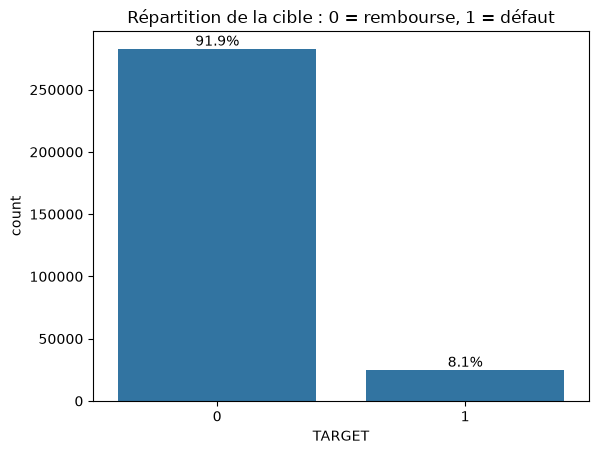

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

ax = sns.countplot(x="TARGET", data=train)
ax.set_title("Répartition de la cible : 0 = rembourse, 1 = défaut")
for p in ax.patches:
    ax.annotate(f"{p.get_height() / len(train):.1%}",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.show()

In [4]:
manquants = (train.isna().mean() * 100).sort_values(ascending=False)
manquants = manquants[manquants > 0]

print(f"{len(manquants)} colonnes sur {train.shape[1]} ont des valeurs manquantes")
print(pd.cut(manquants, bins=[0, 10, 30, 50, 70, 100]).value_counts().sort_index())
manquants.head(20).round(1)

67 colonnes sur 122 ont des valeurs manquantes
(0, 10]      10
(10, 30]      7
(30, 50]      9
(50, 70]     41
(70, 100]     0
Name: count, dtype: int64


COMMONAREA_AVG              69.9
COMMONAREA_MODE             69.9
COMMONAREA_MEDI             69.9
NONLIVINGAPARTMENTS_MEDI    69.4
NONLIVINGAPARTMENTS_MODE    69.4
NONLIVINGAPARTMENTS_AVG     69.4
FONDKAPREMONT_MODE          68.4
LIVINGAPARTMENTS_AVG        68.4
LIVINGAPARTMENTS_MEDI       68.4
LIVINGAPARTMENTS_MODE       68.4
FLOORSMIN_MODE              67.8
FLOORSMIN_AVG               67.8
FLOORSMIN_MEDI              67.8
YEARS_BUILD_AVG             66.5
YEARS_BUILD_MODE            66.5
YEARS_BUILD_MEDI            66.5
OWN_CAR_AGE                 66.0
LANDAREA_MEDI               59.4
LANDAREA_AVG                59.4
LANDAREA_MODE               59.4
dtype: float64

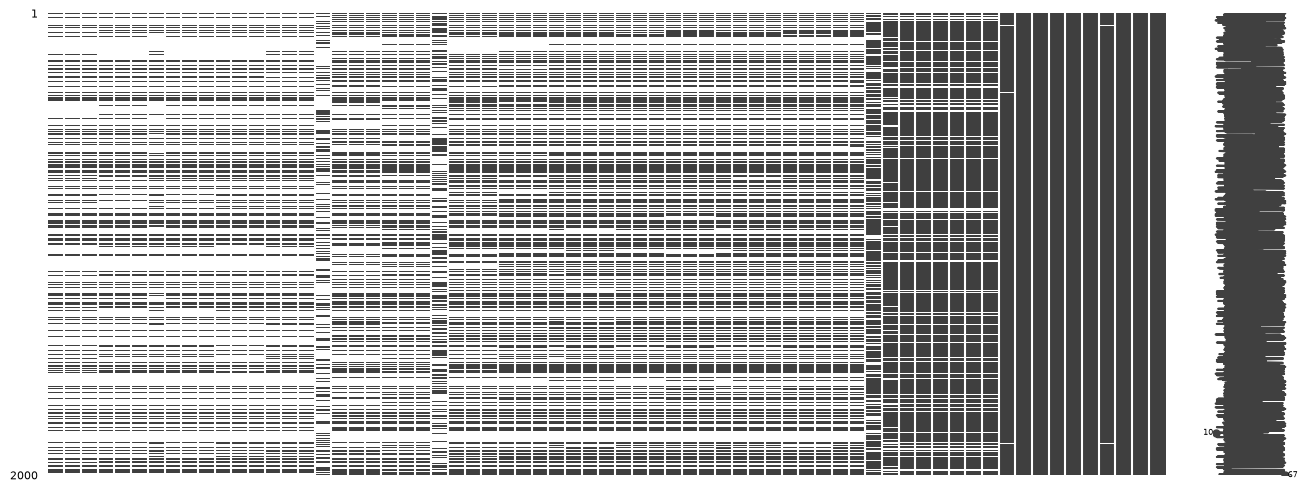

In [5]:
import missingno as msno

msno.matrix(train[manquants.index].sample(2000, random_state=42), figsize=(16, 6), fontsize=7)
plt.show()

In [6]:
cols = ["COMMONAREA_AVG", "YEARS_BUILD_AVG", "OWN_CAR_AGE", "EXT_SOURCE_1", "EXT_SOURCE_3"]

pd.DataFrame({
    "%_vides":            train[cols].isna().mean() * 100,
    "%_defaut_si_vide":   [train.loc[train[c].isna(),  "TARGET"].mean() * 100 for c in cols],
    "%_defaut_si_rempli": [train.loc[train[c].notna(), "TARGET"].mean() * 100 for c in cols],
}).round(1)

,%_vides,%_defaut_si_vide,%_defaut_si_rempli
COMMONAREA_AVG,69.9,8.6,6.9
YEARS_BUILD_AVG,66.5,8.7,6.9
OWN_CAR_AGE,66.0,8.5,7.2
EXT_SOURCE_1,56.4,8.5,7.5
EXT_SOURCE_3,19.8,9.3,7.8


In [7]:
pd.crosstab(train["FLAG_OWN_CAR"], train["OWN_CAR_AGE"].isna(),
            rownames=["Possède une voiture"], colnames=["OWN_CAR_AGE vide"])

OWN_CAR_AGE vide,False,True
Possède une voiture,,
N,0,202924
Y,104582,5


### Valeurs manquantes
- 67 colonnes sur 122 ont des valeurs manquantes, aucune au-delà de 70 % → aucune suppression d'office.
- 41 colonnes entre 50 et 70 % : essentiellement les caractéristiques du logement (triplets AVG / MODE / MEDI), manquantes en bloc.
- Les manquants sont informatifs : le taux de défaut est plus élevé quand la valeur est absente
  (ex. EXT_SOURCE_3 : 9,3 % si vide vs 7,8 % si renseigné). OWN_CAR_AGE est vide pour 100 % des clients sans voiture.
- Stratégie : pas d'imputation pour LightGBM/XGBoost (gestion native des NaN) ;
  imputation médiane + indicateur de manquant pour la régression logistique,
  réalisée **dans le pipeline** pour éviter toute fuite de données en validation croisée.

In [8]:
days = ["DAYS_BIRTH", "DAYS_EMPLOYED", "DAYS_REGISTRATION", "DAYS_ID_PUBLISH", "DAYS_LAST_PHONE_CHANGE"]
(train[days] / -365).describe().round(1)

,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,DAYS_LAST_PHONE_CHANGE
count,307511.0,307511.0,307511.0,307511.0,307510.0
mean,43.9,-174.8,13.7,8.2,2.6
std,12.0,387.1,9.7,4.1,2.3
min,20.5,-1000.7,-0.0,-0.0,-0.0
25%,34.0,0.8,5.5,4.7,0.8
50%,43.2,3.3,12.3,8.9,2.1
75%,53.9,7.6,20.5,11.8,4.3
max,69.1,49.1,67.6,19.7,11.8


In [9]:
anom = train["DAYS_EMPLOYED"] == 365243
print(f"{anom.sum()} clients ({anom.mean():.1%}) ont DAYS_EMPLOYED = 365243")
print(f"Taux de défaut chez eux   : {train.loc[anom, 'TARGET'].mean():.1%}")
print(f"Taux de défaut chez autres: {train.loc[~anom, 'TARGET'].mean():.1%}")
print("\nType de revenu de ces clients :")
print(train.loc[anom, "NAME_INCOME_TYPE"].value_counts())

55374 clients (18.0%) ont DAYS_EMPLOYED = 365243
Taux de défaut chez eux   : 5.4%
Taux de défaut chez autres: 8.7%

Type de revenu de ces clients :
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64


In [10]:
import numpy as np

train["DAYS_EMPLOYED_ANOM"] = (train["DAYS_EMPLOYED"] == 365243).astype(int)
train["DAYS_EMPLOYED"] = train["DAYS_EMPLOYED"].replace(365243, np.nan)

(train["DAYS_EMPLOYED"] / -365).describe().round(1)

C:\Users\A491274\AppData\Local\Temp\ipykernel_6668\625174010.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train["DAYS_EMPLOYED_ANOM"] = (train["DAYS_EMPLOYED"] == 365243).astype(int)


count    252137.0
mean          6.5
std           6.4
min          -0.0
25%           2.1
50%           4.5
75%           8.7
max          49.1
Name: DAYS_EMPLOYED, dtype: float64

In [11]:
corr = train.select_dtypes("number").corr()["TARGET"].drop("TARGET").sort_values()

print("Les 10 plus NÉGATIVES (protègent du défaut) :")
print(corr.head(10).round(3))
print("\nLes 10 plus POSITIVES (augmentent le risque) :")
print(corr.tail(10).round(3))

Les 10 plus NÉGATIVES (protègent du défaut) :
EXT_SOURCE_3                 -0.179
EXT_SOURCE_2                 -0.160
EXT_SOURCE_1                 -0.155
DAYS_EMPLOYED_ANOM           -0.046
FLOORSMAX_AVG                -0.044
FLOORSMAX_MEDI               -0.044
FLOORSMAX_MODE               -0.043
AMT_GOODS_PRICE              -0.040
REGION_POPULATION_RELATIVE   -0.037
ELEVATORS_AVG                -0.034
Name: TARGET, dtype: float64

Les 10 plus POSITIVES (augmentent le risque) :
FLAG_DOCUMENT_3                0.044
REG_CITY_NOT_LIVE_CITY         0.044
FLAG_EMP_PHONE                 0.046
REG_CITY_NOT_WORK_CITY         0.051
DAYS_ID_PUBLISH                0.051
DAYS_LAST_PHONE_CHANGE         0.055
REGION_RATING_CLIENT           0.059
REGION_RATING_CLIENT_W_CITY    0.061
DAYS_EMPLOYED                  0.075
DAYS_BIRTH                     0.078
Name: TARGET, dtype: float64


### Corrélations avec la cible
- Variables les plus liées au défaut : EXT_SOURCE_1/2/3 (scores externes, corr. ≈ -0,16 à -0,18).
- Âge (DAYS_BIRTH) et ancienneté d'emploi (DAYS_EMPLOYED) : les clients jeunes et à faible ancienneté font plus défaut.
- La variable créée DAYS_EMPLOYED_ANOM (retraités / sans emploi) est la 4e plus protectrice (-0,046).
- Corrélations individuelles faibles (< 0,2) : la prédiction reposera sur la combinaison des variables.

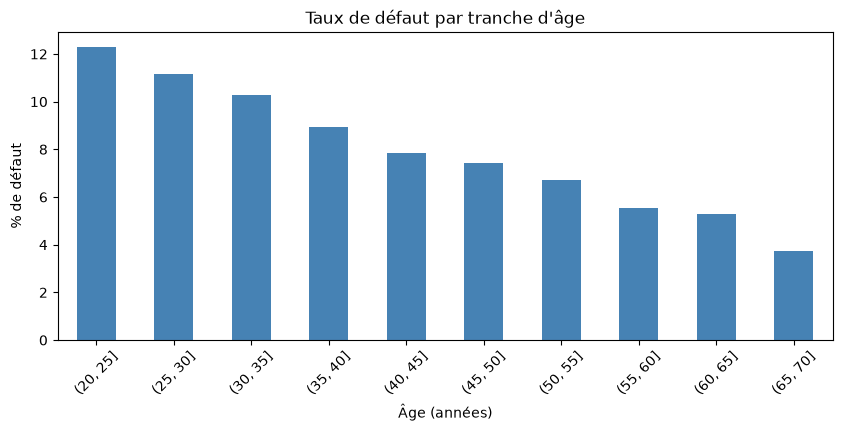

In [12]:
age = train["DAYS_BIRTH"] / -365
tranches = pd.cut(age, bins=range(20, 75, 5))
taux = train.groupby(tranches, observed=True)["TARGET"].mean() * 100

ax = taux.plot(kind="bar", figsize=(10, 4), color="steelblue")
ax.set_title("Taux de défaut par tranche d'âge")
ax.set_xlabel("Âge (années)")
ax.set_ylabel("% de défaut")
plt.xticks(rotation=45)
plt.show()

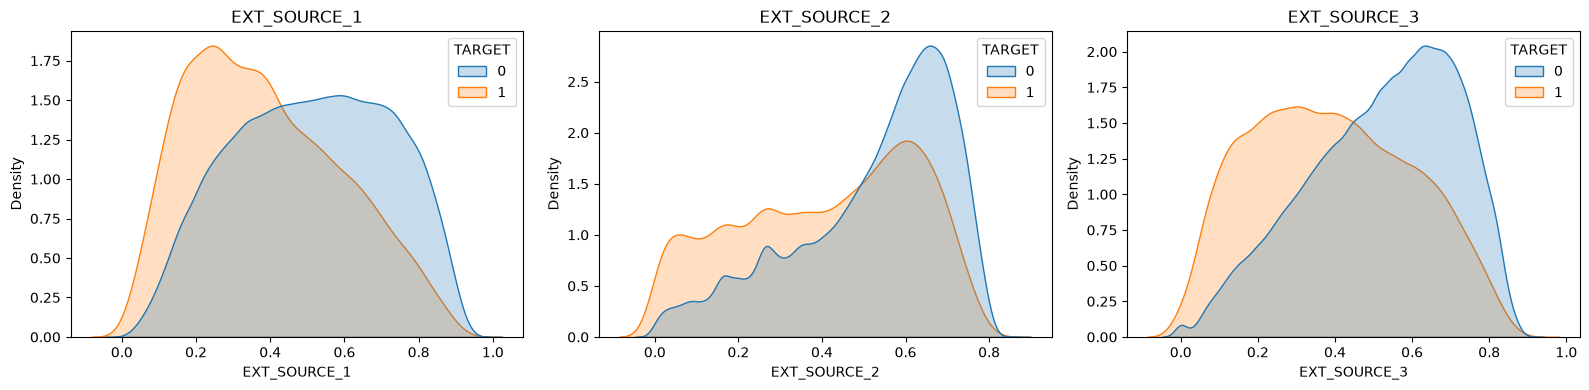

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]):
    sns.kdeplot(data=train, x=col, hue="TARGET", common_norm=False, fill=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### Validation visuelle
- Âge : le taux de défaut décroît régulièrement de 12,3 % (20-25 ans) à 3,7 % (65-70 ans).
- EXT_SOURCE_1/2/3 : les clients en défaut ont des scores plus faibles (EXT_SOURCE_3 sépare le mieux),
  mais les distributions se chevauchent fortement → aucune variable ne suffit seule.

In [14]:
train["CREDIT_INCOME_RATIO"]  = train["AMT_CREDIT"]  / train["AMT_INCOME_TOTAL"]
train["ANNUITY_INCOME_RATIO"] = train["AMT_ANNUITY"] / train["AMT_INCOME_TOTAL"]
train["PAYMENT_RATE"]         = train["AMT_ANNUITY"] / train["AMT_CREDIT"]
train["EMPLOYED_BIRTH_RATIO"] = train["DAYS_EMPLOYED"] / train["DAYS_BIRTH"]
train["EXT_SOURCES_MEAN"]     = train[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].mean(axis=1)

nouvelles = ["CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO", "PAYMENT_RATE",
             "EMPLOYED_BIRTH_RATIO", "EXT_SOURCES_MEAN"]

print("Corrélation avec TARGET :")
print(train[nouvelles].corrwith(train["TARGET"]).round(3))
print("\n% de vides :")
print((train[nouvelles].isna().mean() * 100).round(1))
train[nouvelles].describe().round(2)

Corrélation avec TARGET :
CREDIT_INCOME_RATIO    -0.008
ANNUITY_INCOME_RATIO    0.014
PAYMENT_RATE            0.013
EMPLOYED_BIRTH_RATIO   -0.068
EXT_SOURCES_MEAN       -0.222
dtype: float64

% de vides :
CREDIT_INCOME_RATIO      0.0
ANNUITY_INCOME_RATIO     0.0
PAYMENT_RATE             0.0
EMPLOYED_BIRTH_RATIO    18.0
EXT_SOURCES_MEAN         0.1
dtype: float64


C:\Users\A491274\AppData\Local\Temp\ipykernel_6668\633879385.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train["CREDIT_INCOME_RATIO"]  = train["AMT_CREDIT"]  / train["AMT_INCOME_TOTAL"]
C:\Users\A491274\AppData\Local\Temp\ipykernel_6668\633879385.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train["ANNUITY_INCOME_RATIO"] = train["AMT_ANNUITY"] / train["AMT_INCOME_TOTAL"]
C:\Users\A491274\AppData\Local\Temp\ipykernel_6668\633879385.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result

,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,PAYMENT_RATE,EMPLOYED_BIRTH_RATIO,EXT_SOURCES_MEAN
count,307511.00,307499.00,307499.00,252137.00,307339.00
mean,3.96,0.18,0.05,0.16,0.51
std,2.69,0.09,0.02,0.13,0.15
min,0.00,0.00,0.02,-0.00,0.00
25%,2.02,0.11,0.04,0.06,0.41
50%,3.27,0.16,0.05,0.12,0.52
75%,5.16,0.23,0.06,0.22,0.62
max,84.74,1.88,0.12,0.73,0.88


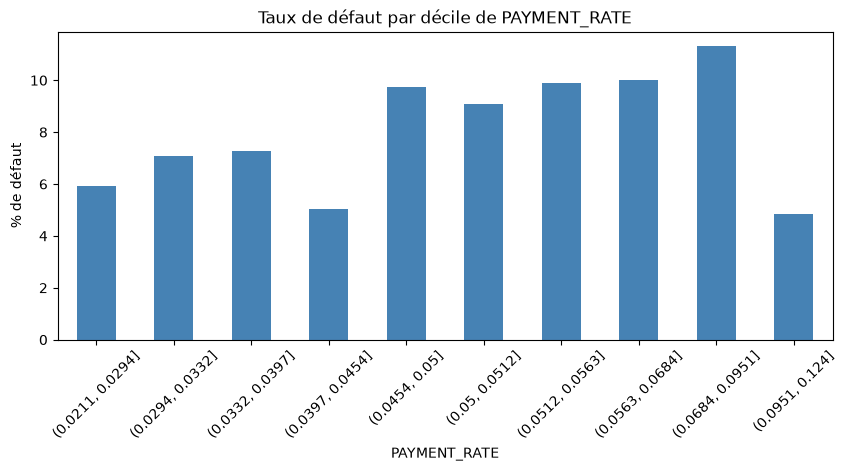

In [15]:
deciles = pd.qcut(train["PAYMENT_RATE"], 10)
taux = train.groupby(deciles, observed=True)["TARGET"].mean() * 100

ax = taux.plot(kind="bar", figsize=(10, 4), color="steelblue")
ax.set_title("Taux de défaut par décile de PAYMENT_RATE")
ax.set_ylabel("% de défaut")
plt.xticks(rotation=45)
plt.show()

- PAYMENT_RATE : corrélation linéaire ≈ 0, mais le taux de défaut varie de 4,8 % à 11,3 % selon le décile
  → lien non linéaire, que les modèles à arbres sauront exploiter.

### Features métier créées
- 5 ratios : CREDIT_INCOME_RATIO, ANNUITY_INCOME_RATIO, PAYMENT_RATE, EMPLOYED_BIRTH_RATIO (Koehrsen) + EXT_SOURCES_MEAN (ajout).
- EXT_SOURCES_MEAN : corrélation -0,222, meilleure que chaque score seul, et seulement 0,1 % de manquants.
- Les ratios financiers ont une corrélation linéaire quasi nulle mais sont conservés :
  le lien peut être non linéaire (cf. graphique par déciles) ; à confirmer par la feature importance.